Same Digital Twin but

    The input to the PID cpontroller is the T_set_point and the T_predicted by PINN
    The output of the PID controller is the heat required to be pumped in to correct error
    The PINN determines the new Temperature at the next time step and that becomes the new input to PID controller.

So instead of the analytical Physics model, we now use the trained PINN.

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

In [4]:
# ==========================================
# 1. CLASSICAL PID CONTROLLER
# ==========================================
class PIDController:
    """
    Standard discrete PID controller with anti-windup clamping.
    """
    def __init__(self, Kp, Ki, Kd, output_limits=(0, 1000), integral_limit=200):
        self.Kp = Kp
        self.Ki = Ki
        self.Kd = Kd
        self.output_limits = output_limits
        self.integral_limit = integral_limit
        self.reset()

    def reset(self):
        self.P_term = 0.0
        self.I_term = 0.0
        self.D_term = 0.0
        self.last_error = 0.0

    def calculate(self, current_temp, setpoint, dt):
        error = setpoint - current_temp

        # Proportional term
        self.P_term = self.Kp * error

        # Integral term with anti-windup clamping
        self.I_term += error * dt
        self.I_term = max(min(self.I_term, self.integral_limit), -self.integral_limit)
        I_output = self.Ki * self.I_term

        # Derivative term
        derivative = (error - self.last_error) / dt if dt > 0 else 0.0
        self.D_term = self.Kd * derivative

        # Actuator output clamped to hardware limits (0 to 1000 W)
        output = self.P_term + I_output + self.D_term
        output = max(min(output, self.output_limits[1]), self.output_limits[0])

        self.last_error = error
        return output

In [5]:
# ==========================================
# 2. PHYSICS-BASED SYSTEM STEP (GROUND TRUTH ODE)
# ==========================================
def simulate_physics_step(current_temp, Q_in, Tamb, dt, tau=500.0, heat_to_temp_factor=1e-3):
    """
    Lumped Capacitance Thermal Model:
    dT/dt = (Tamb - T) / tau + Q_in * factor
    """
    loss_rate = (Tamb - current_temp) / tau
    heat_rate = Q_in * heat_to_temp_factor
    dT = (loss_rate + heat_rate) * dt
    return current_temp + dT

In [6]:
# ==========================================
# 3. CONTROL-AWARE DYNAMIC PINN SURROGATE
# ==========================================
class DynamicOvenPINN(nn.Module):
    """
    State-space neural surrogate mapping:
    [T_norm(t), Q_norm(t)] -> Delta_T_norm
    T(t + dt) = T(t) + Delta_T
    """
    def __init__(self, n_hidden=64, n_layers=3):
        super(DynamicOvenPINN, self).__init__()
        layers = [nn.Linear(2, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers.extend([nn.Linear(n_hidden, n_hidden), nn.Tanh()])
        layers.append(nn.Linear(n_hidden, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, T_norm, Q_norm):
        # inputs are shape (N, 1)
        x = torch.cat([T_norm, Q_norm], dim=1)
        # Output delta change in normalized temperature
        delta_T_norm = self.net(x)
        return T_norm + delta_T_norm

In [7]:
# ==========================================
# 4. TRAINING DATA GENERATION (SYSTEM IDENTIFICATION)
# ==========================================
def generate_training_data(sim_time_s=7200, dt=1.0, T_initial=25.0, Tamb=25.0):
    """
    Generates multi-step excitation data across multiple setpoints
    so the network learns dynamics across the full operating range.
    """
    pid = PIDController(Kp=50.0, Ki=0.01, Kd=5.0, output_limits=(0, 1000))
    steps = int(sim_time_s / dt)

    T_curr = T_initial
    T_list, Q_list, T_next_list = [], [], []

    # Step changes in setpoint to explore system transient and steady state
    setpoints = [100.0, 180.0, 140.0, 220.0]
    segment = steps // len(setpoints)

    for step in range(steps):
        sp = setpoints[min(step // segment, len(setpoints) - 1)]
        # Add slight random perturbation to explore non-perfect control trajectories
        Q_in = pid.calculate(T_curr, sp, dt)
        if step % 20 == 0:
            Q_in = np.clip(Q_in + np.random.uniform(-50, 50), 0, 1000)

        T_next = simulate_physics_step(T_curr, Q_in, Tamb, dt)

        T_list.append(T_curr)
        Q_list.append(Q_in)
        T_next_list.append(T_next)

        T_curr = T_next

    return (
        torch.tensor(T_list, dtype=torch.float32).unsqueeze(1),
        torch.tensor(Q_list, dtype=torch.float32).unsqueeze(1),
        torch.tensor(T_next_list, dtype=torch.float32).unsqueeze(1)
    )

In [8]:
# ==========================================
# 5. PINN TRAINING WITH ODE RESIDUAL LOSS
# ==========================================
def train_dynamic_pinn(model, T_data, Q_data, T_next_data, epochs=3000, lr=1e-3,
                       Tamb=25.0, tau=500.0, factor=1e-3, dt=1.0, T_max=300.0, Q_max=1000.0):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    mse_loss = nn.MSELoss()

    # Normalization
    T_norm = T_data / T_max
    Q_norm = Q_data / Q_max
    T_next_norm = T_next_data / T_max

    # Collocation points for physics loss across arbitrary (T, Q) space
    N_colloc = 2000
    T_colloc = torch.rand(N_colloc, 1) * T_max
    Q_colloc = torch.rand(N_colloc, 1) * Q_max

    T_colloc_norm = T_colloc / T_max
    Q_colloc_norm = Q_colloc / Q_max

    print("Training Dynamic PINN Surrogate...")
    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()

        # 1. Supervised Data Loss
        pred_next_norm = model(T_norm, Q_norm)
        loss_data = mse_loss(pred_next_norm, T_next_norm)

        # 2. Physics ODE Residual Loss
        # Residual = (T_next - T) / dt - [(Tamb - T)/tau + Q*factor]
        pred_colloc_next_norm = model(T_colloc_norm, Q_colloc_norm)
        pred_colloc_next = pred_colloc_next_norm * T_max

        dT_dt_pred = (pred_colloc_next - T_colloc) / dt
        ode_target = (Tamb - T_colloc) / tau + (Q_colloc * factor)
        loss_physics = torch.mean((dT_dt_pred - ode_target) ** 2)

        # Total combined loss
        total_loss = loss_data + 0.1 * loss_physics

        total_loss.backward()
        optimizer.step()

        if epoch % 500 == 0 or epoch == 1:
            print(f"Epoch {epoch:4d}/{epochs} | Total: {total_loss.item():.6f} | "
                  f"Data Loss: {loss_data.item():.6f} | Physics Residual: {loss_physics.item():.6f}")

    print("Training complete.\n")
    return model

In [9]:
# ==========================================
# 6. DIGITAL TWIN CLOSED-LOOP SIMULATION
# ==========================================
def run_digital_twin_simulation():
    # Parameters
    T_INITIAL = 25.0
    T_SETPOINT = 180.0
    T_AMBIENT = 25.0
    SIM_TIME_S = 3600.0  # 1 hour
    DT = 1.0
    T_MAX = 300.0
    Q_MAX = 1000.0

    # 1. Generate multi-condition training data & train PINN
    T_train, Q_train, T_next_train = generate_training_data(sim_time_s=7200, dt=DT)
    pinn = DynamicOvenPINN(n_hidden=64, n_layers=3)
    pinn = train_dynamic_pinn(pinn, T_train, Q_train, T_next_train, epochs=2500, T_max=T_MAX, Q_max=Q_MAX)
    pinn.eval()

    # 2. Setup Closed-Loop Controller
    pid_twin = PIDController(Kp=50.0, Ki=0.01, Kd=5.0, output_limits=(0, 1000))

    # Initialize tracking variables
    T_pinn = T_INITIAL
    T_phys_baseline = T_INITIAL

    time_series = [0.0]
    T_pinn_series = [T_INITIAL]
    T_phys_series = [T_INITIAL]
    T_setpoint_series = [T_SETPOINT]
    Q_in_series = [0.0]

    steps = int(SIM_TIME_S / DT)
    print("Starting Digital Twin Closed-Loop Run...")

    for step in range(steps):
        # A. PID reads PINN temperature and computes heat power Q_in
        Q_in = pid_twin.calculate(T_pinn, T_SETPOINT, DT)
        Q_in_series.append(Q_in)

        # B. PINN advances dynamically based on current T and control input Q_in
        T_norm = torch.tensor([[T_pinn / T_MAX]], dtype=torch.float32)
        Q_norm = torch.tensor([[Q_in / Q_MAX]], dtype=torch.float32)

        with torch.no_grad():
            T_pinn_next_norm = pinn(T_norm, Q_norm)
            T_pinn = T_pinn_next_norm.item() * T_MAX

        # C. Independent physical plant receives the EXACT same Q_in (Ground Truth Check)
        T_phys_baseline = simulate_physics_step(T_phys_baseline, Q_in, T_AMBIENT, DT)

        # Log metrics
        t_min = (step + 1) * DT / 60.0
        time_series.append(t_min)
        T_pinn_series.append(T_pinn)
        T_phys_series.append(T_phys_baseline)
        T_setpoint_series.append(T_SETPOINT)

    # 3. Plotting Verification
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

    # Temperature tracking plot
    ax1.plot(time_series, T_setpoint_series, 'r--', label='Set Point Target (180°C)')
    ax1.plot(time_series, T_phys_series, 'b-', linewidth=2, label='True Physics Ground Truth')
    ax1.plot(time_series, T_pinn_series, 'g:', linewidth=3, label='PINN-Controlled Surrogate State')
    ax1.set_ylabel('Temperature (°C)')
    ax1.set_title('Corrected Closed-Loop Digital Twin: Dynamic PINN In-The-Loop')
    ax1.grid(True)
    ax1.legend(loc='lower right')

    # Actuator heating power plot
    ax2.plot(time_series, Q_in_series, 'm-', label='Actuator Input $Q_{in}$ (Watts)')
    ax2.set_xlabel('Time (Minutes)')
    ax2.set_ylabel('Heater Power (W)')
    ax2.grid(True)
    ax2.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

Training Dynamic PINN Surrogate...
Epoch    1/2500 | Total: 452.005737 | Data Loss: 0.045960 | Physics Residual: 4519.597656
Epoch  500/2500 | Total: 0.000721 | Data Loss: 0.000000 | Physics Residual: 0.007209
Epoch 1000/2500 | Total: 0.000151 | Data Loss: 0.000000 | Physics Residual: 0.001506
Epoch 1500/2500 | Total: 0.000082 | Data Loss: 0.000000 | Physics Residual: 0.000823
Epoch 2000/2500 | Total: 0.000060 | Data Loss: 0.000000 | Physics Residual: 0.000599
Epoch 2500/2500 | Total: 0.000052 | Data Loss: 0.000000 | Physics Residual: 0.000521
Training complete.

Starting Digital Twin Closed-Loop Run...


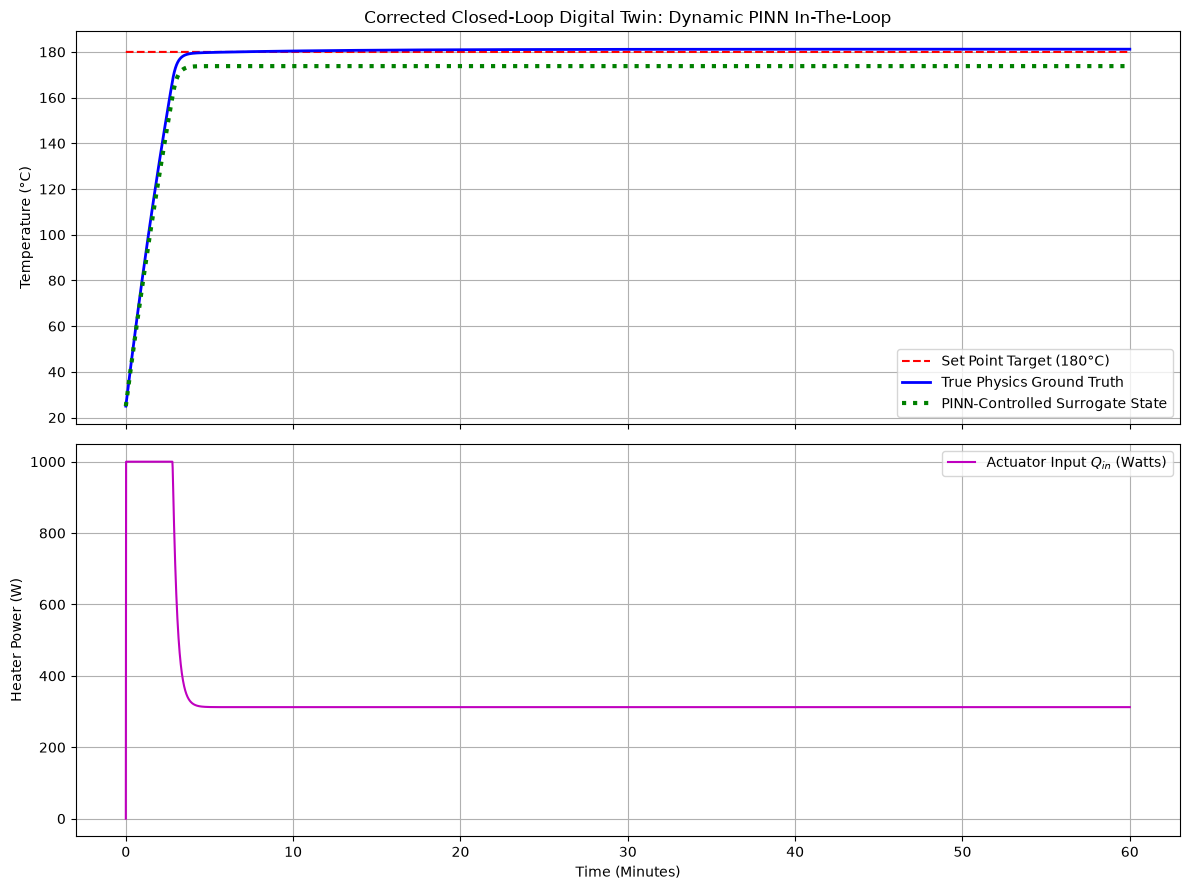

In [10]:
run_digital_twin_simulation()

Notebook 4b: Closing the Loop with the PINN as the Digital TwinConcept: 
- Transitioning from passive estimation to an active virtual surrogate.
- Mechanism:The PID controller’s error calculation changes from error = setpoint - T_phys to error = setpoint - T_controlled (where T_controlled is supplied directly by pinn_model).
- The PINN's output at step $t$ directly dictates the actuator command $Q_{in}$ for step $t+1$.
- The classical physics model is decoupled from the controller and kept strictly as an offline ground-truth baseline.  